In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
feature_map = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 3],
    [1, 4, 2, 9]
], dtype=float)
print(feature_map)

[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [1. 4. 2. 9.]]


In [3]:
def pooling2d(array, size=2, mode="max", stride=2):
    h, w = array.shape
    out_h = (h - size) // stride + 1
    out_w = (w - size) // stride + 1
    output = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = array[i*stride:i*stride+size, j*stride:j*stride+size]
            output[i, j] = np.max(patch) if mode == "max" else np.mean(patch)
    return output

max_result = pooling2d(feature_map, mode="max")
avg_result = pooling2d(feature_map, mode="average")
print("Max pooling:\n", max_result)
print("Average pooling:\n", avg_result)

Max pooling:
 [[6. 4.]
 [7. 9.]]
Average pooling:
 [[3.75 2.25]
 [3.5  5.5 ]]


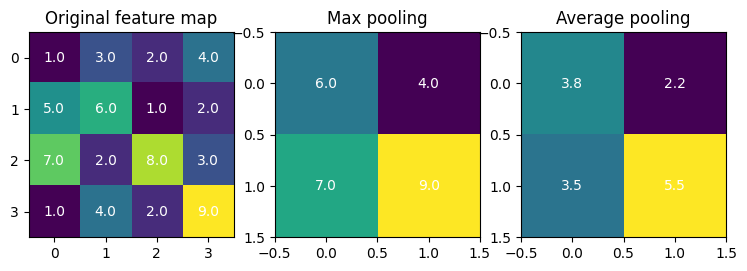

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, data, title in zip(
    axes, [feature_map, max_result, avg_result],
    ["Original feature map", "Max pooling", "Average pooling"]
):
    ax.imshow(data, cmap="viridis")
    ax.set_title(title)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data[i,j]:.1f}", ha="center", va="center", color="white")
plt.show()